# Notebook 02 – Data Exploration and Cleaning

## What is this notebook for?
We look carefully at the raw data before changing anything.  
We find missing values, duplicates, and decide which markets and commodities to keep.

## Why do we need this stage?
- Missing values and duplicates can make the model learn wrong patterns.
- We must choose only maize and beans (our target crops) and only retail prices.
- Selecting markets with long history gives us better time-series data.


## Step 2.1 – Load the data and filter for maize and beans (Retail only)


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv('../data/raw/wfp_food_prices_uga.csv')
df['date'] = pd.to_datetime(df['date'])

mask = (
    (df['commodity'].isin(['Maize (white)', 'Beans'])) &
    (df['pricetype'] == 'Retail') &
    (df['unit'] == 'KG')
)
mb = df.loc[mask].copy()
mb['commodity'] = mb['commodity'].replace({'Maize (white)': 'Maize'})

print("Shape after filtering for Maize and Beans (Retail):", mb.shape)
print(mb['commodity'].value_counts())


Shape after filtering for Maize and Beans (Retail): (6217, 16)
commodity
Beans    3149
Maize    3068
Name: count, dtype: int64


## Step 2.2 – Choose major markets with long history


In [2]:
print("Records per market (top 15):")
print(mb['market'].value_counts().head(15))

major_markets = ['Owino', 'Lira', 'Gulu', 'Mbarara', 'Iganga', 'Busia', 'Jinja', 'Kapchorwa', 'Mbale']
mb = mb[mb['market'].isin(major_markets)].copy()
print("\nShape after keeping major markets:", mb.shape)
print(mb.groupby(['market', 'commodity']).size().unstack(fill_value=0))


Records per market (top 15):
market
Owino                              362
Lira                               352
Gulu                               340
Mbarara                            332
Iganga                             309
Kapchorwa                          263
Jinja                              193
Kaabong                            168
Kotido                             158
Makaratin                          154
Namalu                             154
Mbale                              143
Adjumani (refugee settlement)      138
Imvepi (refugee settlement)        138
Rhino Camp (refugee settlement)    138
Name: count, dtype: int64

Shape after keeping major markets: (2384, 16)
commodity  Beans  Maize
market                 
Busia         45     45
Gulu         170    170
Iganga       155    154
Jinja         96     97
Kapchorwa    132    131
Lira         186    166
Mbale         74     69
Mbarara      168    164
Owino        200    162


## Step 2.3 – Graph 1: Records per market after filtering


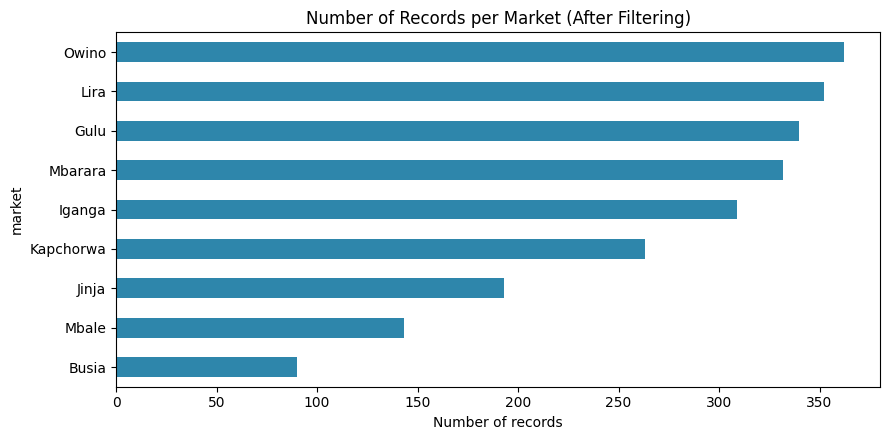

In [3]:
plt.figure(figsize=(9, 4.5))
mb['market'].value_counts().sort_values().plot(kind='barh', color='#2E86AB')
plt.title('Number of Records per Market (After Filtering)')
plt.xlabel('Number of records')
plt.tight_layout()
plt.savefig('../figures/02_records_per_market.png', dpi=120, bbox_inches='tight')
plt.show()


## Step 2.4 – Check duplicates and missing values


In [4]:
mb = mb[['date', 'admin1', 'market', 'latitude', 'longitude', 'commodity', 'price']].copy()
mb = mb.sort_values(['market', 'commodity', 'date']).reset_index(drop=True)

dup_count = mb.duplicated(subset=['market', 'commodity', 'date']).sum()
print("Number of exact duplicate rows:", dup_count)

if dup_count > 0:
    mb = mb.groupby(['date', 'admin1', 'market', 'latitude', 'longitude', 'commodity'], as_index=False)['price'].mean()
    print("Duplicates averaged and removed.")

print("\nMissing values per column:")
print(mb.isna().sum())


Number of exact duplicate rows: 0

Missing values per column:
date         0
admin1       0
market       0
latitude     0
longitude    0
commodity    0
price        0
dtype: int64


## Step 2.5 – Create a clean monthly panel


In [5]:
wide = mb.pivot_table(
    index=['date', 'admin1', 'market', 'latitude', 'longitude'],
    columns='commodity',
    values='price',
    aggfunc='mean'
).reset_index()
wide.columns.name = None
wide = wide.rename(columns={'Maize': 'maize_price', 'Beans': 'beans_price'})
wide['year'] = wide['date'].dt.year
wide['month'] = wide['date'].dt.month

print("Clean panel shape:", wide.shape)
print("Missing maize prices:", wide['maize_price'].isna().sum())
print("Missing beans prices:", wide['beans_price'].isna().sum())


Clean panel shape: (1233, 9)
Missing maize prices: 75
Missing beans prices: 7


## Step 2.6 – Graph 2: Missing values bar chart


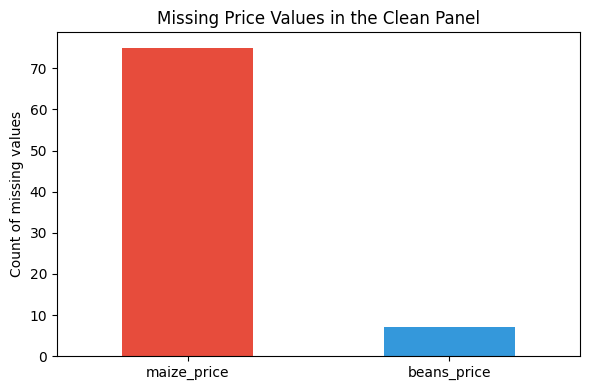

In [6]:
plt.figure(figsize=(6, 4))
miss = wide[['maize_price', 'beans_price']].isna().sum()
miss.plot(kind='bar', color=['#E74C3C', '#3498DB'])
plt.title('Missing Price Values in the Clean Panel')
plt.ylabel('Count of missing values')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('../figures/02_missing_values.png', dpi=120, bbox_inches='tight')
plt.show()


## Step 2.7 – Graph 3: Price distribution histograms


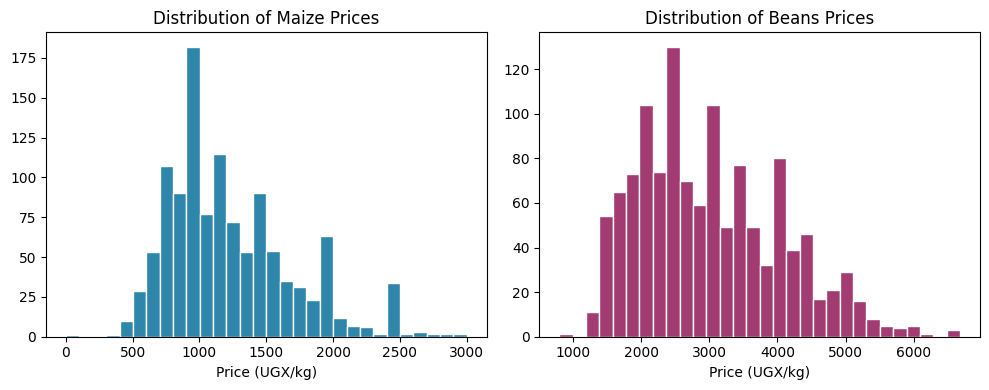

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(wide['maize_price'].dropna(), bins=30, color='#2E86AB', edgecolor='white')
axes[0].set_title('Distribution of Maize Prices')
axes[0].set_xlabel('Price (UGX/kg)')
axes[1].hist(wide['beans_price'].dropna(), bins=30, color='#A23B72', edgecolor='white')
axes[1].set_title('Distribution of Beans Prices')
axes[1].set_xlabel('Price (UGX/kg)')
plt.tight_layout()
plt.savefig('../figures/02_price_distributions.png', dpi=120, bbox_inches='tight')
plt.show()


## Step 2.8 – Graph 4: Box plots by market


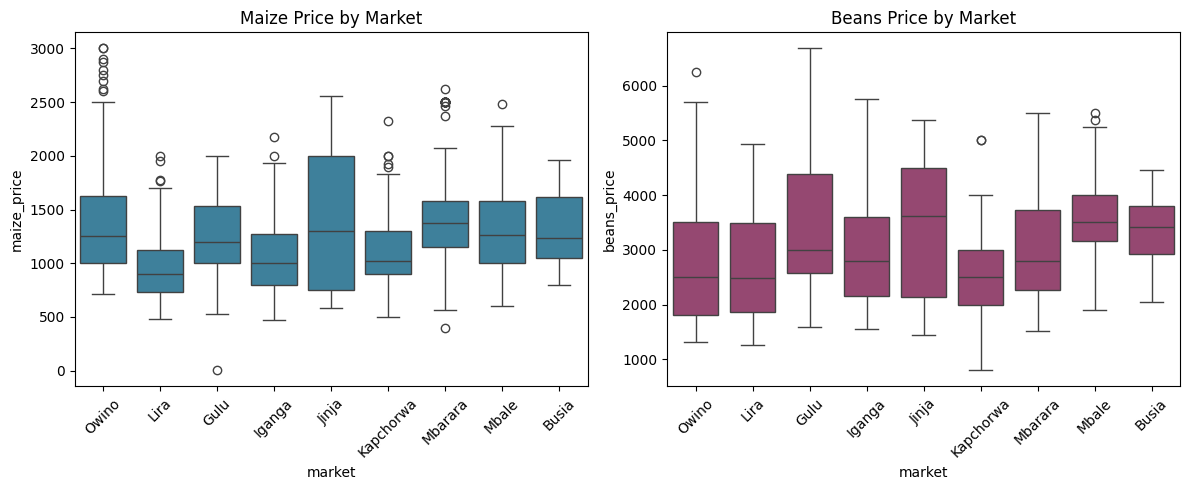

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(data=wide, x='market', y='maize_price', ax=axes[0], color='#2E86AB')
axes[0].set_title('Maize Price by Market')
axes[0].tick_params(axis='x', rotation=45)
sns.boxplot(data=wide, x='market', y='beans_price', ax=axes[1], color='#A23B72')
axes[1].set_title('Beans Price by Market')
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig('../figures/02_boxplots_by_market.png', dpi=120, bbox_inches='tight')
plt.show()


## Step 2.9 – Save the cleaned panel


In [9]:
wide.to_csv('../data/cleaned/uganda_maize_beans_retail_panel.csv', index=False)
print("Saved: data/cleaned/uganda_maize_beans_retail_panel.csv")
print("Date range:", wide['date'].min().date(), "to", wide['date'].max().date())
print("Markets kept:", sorted(wide['market'].unique().tolist()))


Saved: data/cleaned/uganda_maize_beans_retail_panel.csv
Date range: 2008-10-15 to 2026-04-15
Markets kept: ['Busia', 'Gulu', 'Iganga', 'Jinja', 'Kapchorwa', 'Lira', 'Mbale', 'Mbarara', 'Owino']
